* Найти графовый набор данных для решения задачи предсказания (классификация вершин, обнаружение сообществ и т.д.).
* Использовать несколько слоев GCNConv из библиотеки PyG для построения GCN модели.
* Обучить полученную модель, подобрать гиперпараметры (например, learning rate) на валидационной выборке, и оценить качество предсказания на тестовой выборке.

# Датасет
Возьмем датасет [Cora](https://paperswithcode.com/dataset/cora).

In [ ]:
import torch
import torch.nn.functional as F
from torch_geometric.datasets import Planetoid
from torch_geometric.nn import GCNConv
from torch_geometric.transforms import NormalizeFeatures
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

dataset = Planetoid(root='/tmp/Cora', name='Cora', transform=NormalizeFeatures())
data = dataset[0]

print(f'Dataset: {dataset.name}')
print(f'Number of graphs: {len(dataset)}')
print(f'Number of features: {dataset.num_features}')
print(f'Number of classes: {dataset.num_classes}')
print(f'Number of nodes: {data.num_nodes}')
print(f'Number of edges: {data.num_edges}')
print(f'Number of training nodes: {data.train_mask.sum()}')
print(f'Number of validation nodes: {data.val_mask.sum()}')
print(f'Number of test nodes: {data.test_mask.sum()}')
print(f'Is undirected: {data.is_undirected()}')
print(f'Has self-loops: {data.contains_self_loops()}')

Dataset: Cora
Number of graphs: 1
Number of features: 1433
Number of classes: 7
Number of nodes: 2708
Number of edges: 10556
Number of training nodes: 140
Number of validation nodes: 500
Number of test nodes: 1000
Is undirected: True
Has self-loops: False


# Модель GCN
Будем использовать ReLU между слоев и Linear для классификации.

In [5]:
class GCN(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, num_layers):
        super().__init__()
        self.num_layers = num_layers
        self.conv_layers = torch.nn.ModuleList()
        
        self.conv_layers.append(GCNConv(in_channels, hidden_channels))
        
        for _ in range(num_layers - 2):
            self.conv_layers.append(GCNConv(hidden_channels, hidden_channels))
            
        self.conv_layers.append(GCNConv(hidden_channels, out_channels))

    def forward(self, x, edge_index):
        for i, conv in enumerate(self.conv_layers):
            x = conv(x, edge_index)
            if i < self.num_layers - 1:
                x = F.relu(x)
                x = F.dropout(x, p=0.5, training=self.training)
        return x

# Обучение и подбор гиперпараметров

In [6]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
data = data.to(device)

def train(model, data, optimizer):
    model.train()
    optimizer.zero_grad()
    out = model(data.x, data.edge_index)
    loss = F.cross_entropy(out[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer.step()
    return loss.item()

@torch.no_grad()
def evaluate(model, data, mask):
    model.eval()
    out = model(data.x, data.edge_index)
    pred = out[mask].argmax(dim=1)
    correct = (pred == data.y[mask]).sum()
    acc = int(correct) / int(mask.sum())
    return acc

hidden_channels = 16

learning_rates = [0.01, 0.005, 0.001]
num_gcn_layers_options = [2, 3, 4]

best_val_accuracy = 0
best_model = None
best_hyperparams = {}

results = {}

for lr in learning_rates:
    for num_layers in num_gcn_layers_options:
        print(f"\nTraining with Learning Rate: {lr}, Number of Layers: {num_layers}")
        model = GCN(dataset.num_features, hidden_channels, dataset.num_classes, num_layers).to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=5e-4)
        
        history = {'train_loss': [], 'val_accuracy': [], 'test_accuracy': []}

        for epoch in range(1, 201):
            loss = train(model, data, optimizer)
            train_acc = evaluate(model, data, data.train_mask)
            val_acc = evaluate(model, data, data.val_mask)
            test_acc = evaluate(model, data, data.test_mask)

            history['train_loss'].append(loss)
            history['val_accuracy'].append(val_acc)
            history['test_accuracy'].append(test_acc)
            
            if epoch % 20 == 0:
                print(f'Epoch: {epoch:03d}, Loss: {loss:.4f}, Train Acc: {train_acc:.4f}, Val Acc: {val_acc:.4f}, Test Acc: {test_acc:.4f}')

        results[(lr, num_layers)] = history

        final_val_acc = history['val_accuracy'][-1]
        if final_val_acc > best_val_accuracy:
            best_val_accuracy = final_val_acc
            best_model = model
            best_hyperparams = {'learning_rate': lr, 'num_layers': num_layers}

print("\n--- Hyperparameter Tuning Complete ---")
print(f"Best Validation Accuracy: {best_val_accuracy:.4f}")
print(f"Best Hyperparameters: {best_hyperparams}")

if best_model:
    final_test_accuracy = evaluate(best_model, data, data.test_mask)
    print(f"Final Test Accuracy with Best Model: {final_test_accuracy:.4f}")


Training with Learning Rate: 0.01, Number of Layers: 2
Epoch: 020, Loss: 1.6964, Train Acc: 0.9429, Val Acc: 0.7300, Test Acc: 0.7290
Epoch: 040, Loss: 1.3312, Train Acc: 0.9500, Val Acc: 0.7520, Test Acc: 0.7500
Epoch: 060, Loss: 0.9043, Train Acc: 0.9786, Val Acc: 0.7880, Test Acc: 0.7950
Epoch: 080, Loss: 0.7233, Train Acc: 0.9857, Val Acc: 0.8000, Test Acc: 0.8020
Epoch: 100, Loss: 0.5000, Train Acc: 0.9857, Val Acc: 0.7880, Test Acc: 0.8230
Epoch: 120, Loss: 0.4516, Train Acc: 0.9857, Val Acc: 0.7880, Test Acc: 0.8070
Epoch: 140, Loss: 0.3992, Train Acc: 1.0000, Val Acc: 0.7920, Test Acc: 0.8110
Epoch: 160, Loss: 0.3762, Train Acc: 0.9929, Val Acc: 0.7880, Test Acc: 0.8110
Epoch: 180, Loss: 0.3802, Train Acc: 1.0000, Val Acc: 0.7920, Test Acc: 0.8160
Epoch: 200, Loss: 0.3561, Train Acc: 1.0000, Val Acc: 0.7880, Test Acc: 0.8110

Training with Learning Rate: 0.01, Number of Layers: 3
Epoch: 020, Loss: 1.6661, Train Acc: 0.8071, Val Acc: 0.6060, Test Acc: 0.5760
Epoch: 040, Loss: 0

# Результаты

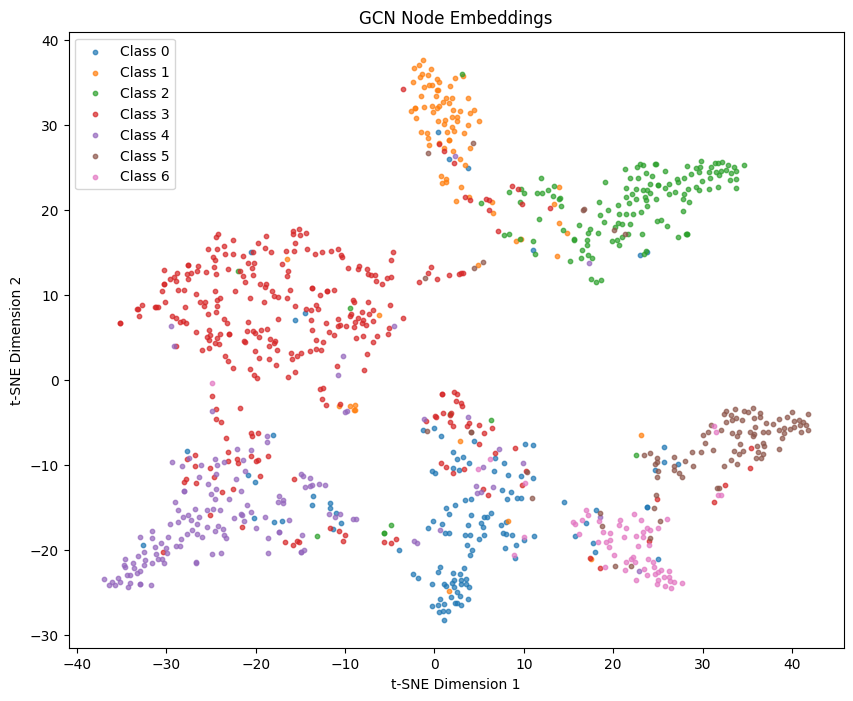

In [8]:
def visualize_embeddings(embeddings, colors, title="Node Embeddings"):
    tsne = TSNE(n_components=2, random_state=42, perplexity=30)
    embeddings_2d = tsne.fit_transform(embeddings.cpu().numpy())

    plt.figure(figsize=(10, 8))
    for i in range(dataset.num_classes):
        indices = (colors == i).nonzero(as_tuple=True)[0]
        plt.scatter(embeddings_2d[indices, 0], embeddings_2d[indices, 1], label=f'Class {i}', alpha=0.7, s=10)
    plt.title(title)
    plt.xlabel("t-SNE Dimension 1")
    plt.ylabel("t-SNE Dimension 2")
    plt.legend()
    plt.show()

if best_model:
    best_model.eval()
    with torch.no_grad():
        final_embeddings = best_model(data.x, data.edge_index)
    
    visualize_embeddings(final_embeddings[data.test_mask], data.y[data.test_mask], "GCN Node Embeddings")

# Заключение
График показывает, что GCN успешно научился различать классы, так как большинство точек одного цвета (класса) группируются вместе, образуя отдельные кластеры.